# So sánh các mô hình dự đoán giá bất động sản

Notebook chạy **trên máy local** (không qua Docker/Airflow/MLflow) để xem kết quả của 3 mô hình boosting:
HistGradientBoosting, XGBoost, CatBoost. (Ridge và RandomForest đã bị loại vì kém hơn rõ:
MAPE 26,8% và 21,0%.)

Logic giống `scripts/train_price_model.py`: cùng tập đặc trưng, cùng cách chia train/test theo thời gian,
cùng chỉ số. Khác biệt duy nhất: không đăng ký mô hình, không ghi bảng dự đoán.

**Chạy:** cần MinIO đang bật (`docker compose up -d minio`), rồi
`.venv/bin/jupyter lab notebooks/price_model_comparison.ipynb`.

## 1. Đọc dữ liệu `gold.ml_price_features` từ MinIO

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from deltalake import DeltaTable
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
from xgboost import XGBRegressor

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.axisbelow": True})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9893"

TABLE = "s3://lakehouse/warehouse/gold.db/ml_price_features"
STORAGE = {
    "AWS_ENDPOINT_URL": os.getenv("MINIO_ENDPOINT", "http://localhost:9000"),
    "AWS_ACCESS_KEY_ID": os.getenv("MINIO_ACCESS_KEY", "minio"),
    "AWS_SECRET_ACCESS_KEY": os.getenv("MINIO_SECRET_KEY", "minio123"),
    "AWS_REGION": "us-east-1",
    "AWS_ALLOW_HTTP": "true",
}
table = DeltaTable(TABLE, storage_options=STORAGE)
df = table.to_pandas()
# Mã quận/phường là nhãn phân loại, không phải số lượng.
df["district_id"] = df["district_id"].astype("string").astype(object)
df["ward_id"] = df["ward_id"].astype("string").astype(object)
df["posted_date"] = pd.to_datetime(df["posted_date"])
print(f"Delta version {table.version()}: {len(df):,} dòng x {df.shape[1]} cột")
df[["listing_key", "posted_date", "district", "property_type", "area_m2", "price_vnd"]].head()

Delta version 23: 37,945 dòng x 42 cột


,listing_key,posted_date,district,property_type,area_m2,price_vnd
0,617c58b83e0d1540d0b2e7102b60ac50ce6fce4a4af5b2...,2026-09-20,Quận Bình Tân,Đất,80.0000,9000000000
1,c303afc7462d0dfc4504d9d63a087c6e05fbd1914f3549...,2026-09-05,Thành phố Thủ Đức,Đất,81.1998,4500000000
2,a7531335e1d12c2ead67ea901bf5875144ec4857ebcd5a...,2026-09-05,Quận Gò Vấp,Đất,188.0000,18000000000
3,f4446d47a5c3d4a6218fae98719d31deea9faf8c800d7f...,2026-09-05,Quận Gò Vấp,Nhà ở,58.0000,6950000000
4,9d37fa1a8af291263daa0921756e305a6de1e2efc6e536...,2026-09-05,Huyện Nhà Bè,Nhà ở,23.0000,1680000000


In [2]:
summary = df.groupby("property_type").agg(
    so_tin=("price_vnd", "size"),
    gia_trung_vi_ty=("price_vnd", lambda s: s.median() / 1e9),
    dien_tich_trung_vi=("area_m2", "median"),
)
summary

,so_tin,gia_trung_vi_ty,dien_tich_trung_vi
property_type,,,
Căn hộ/Chung cư,5704,3.6000,68.0000
Nhà ở,27145,5.9900,56.0000
Đất,5096,4.6500,111.0999


## 2. Đặc trưng và tiền xử lý dùng chung

In [3]:
TARGET = "log_price_vnd"
NUMERIC = ["area_m2", "living_area_m2", "width_m", "length_m", "bedrooms", "bathrooms",
           "total_floors", "floor_number", "latitude", "longitude"]
BOOLEAN = ["is_in_project", "has_car_alley", "is_frontage", "is_wide_back", "is_narrow_back",
           "is_dilapidated", "is_not_completed", "is_planning_affected", "has_certificate"]
LOW_CARD = ["district_id", "area_zone", "district_type", "property_type", "property_subtype",
            "house_direction", "furnishing", "handover_status", "legal_category"]
HIGH_CARD = ["ward_id", "street", "project_name"]
CATEGORICAL = LOW_CARD + HIGH_CARD
FEATURES = NUMERIC + BOOLEAN + CATEGORICAL
MISSING = "__missing__"


def prepare(frame):
    out = frame.copy()
    for c in NUMERIC:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype("float64")
    for c in BOOLEAN:
        out[c] = out[c].map({True: 1.0, False: 0.0}).astype("float64")
    for c in CATEGORICAL:
        out[c] = out[c].astype("object").where(out[c].notna(), MISSING).astype(str)
    return out[FEATURES]


missing = df[FEATURES].isna().mean().sort_values(ascending=False)
print(f"{len(FEATURES)} đặc trưng; tỷ lệ thiếu của các cột thiếu nhiều nhất:")
(missing[missing > 0].head(10) * 100).round(1).rename("% thiếu").to_frame()

31 đặc trưng; tỷ lệ thiếu của các cột thiếu nhiều nhất:


,% thiếu
floor_number,96.7000
handover_status,90.0000
project_name,86.9000
house_direction,75.3000
living_area_m2,63.8000
furnishing,58.3000
total_floors,47.4000
bathrooms,36.3000
length_m,34.2000
width_m,31.9000


## 3. Chia train/test theo thời gian

10 ngày đăng tin gần nhất làm tập test. Mô hình phải dự đoán tin đăng **sau** mọi thứ nó đã học,
giống như khi dùng thật.

In [4]:
TEST_DAYS = 10
cutoff = df["posted_date"].max() - pd.Timedelta(days=TEST_DAYS)
is_test = df["posted_date"] > cutoff
train, test = df[~is_test], df[is_test]
x_train, x_test = prepare(train), prepare(test)
y_train = train[TARGET].astype(float)
print(f"train: {len(train):,} dòng ({train.posted_date.min():%Y-%m-%d} -> {train.posted_date.max():%Y-%m-%d})")
print(f"test : {len(test):,} dòng ({test.posted_date.min():%Y-%m-%d} -> {test.posted_date.max():%Y-%m-%d})")

train: 32,197 dòng (2025-07-24 -> 2026-10-18)
test : 5,748 dòng (2026-10-19 -> 2026-10-28)


## 4. Ba mô hình ứng viên

| Mô hình | Tiền xử lý | Ghi chú |
|---|---|---|
| HistGBM | ordinal + target encoding | boosting, early stopping |
| XGBoost | ordinal + target encoding | boosting có regularization, lấy mẫu dòng/cột |
| CatBoost | **không** – tự mã hóa biến phân loại (ordered target statistics) | |

In [5]:
def high_card_encoder():
    return make_pipeline(SimpleImputer(strategy="constant", fill_value=MISSING),
                         TargetEncoder(target_type="continuous", random_state=42))


def tree_prep():
    return ColumnTransformer([
        ("num", "passthrough", NUMERIC + BOOLEAN),
        ("low", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               dtype=np.float64), LOW_CARD),
        ("high", high_card_encoder(), HIGH_CARD),
    ], verbose_feature_names_out=False).set_output(transform="pandas")



candidates = {
    "hist_gbm": Pipeline([("prep", tree_prep()), ("model", HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=2000, max_leaf_nodes=63, min_samples_leaf=20,
        l2_regularization=1.0, categorical_features=LOW_CARD, early_stopping=True,
        validation_fraction=0.1, n_iter_no_change=50, random_state=42))]),
    "xgboost": Pipeline([("prep", tree_prep()), ("model", XGBRegressor(
        n_estimators=800, learning_rate=0.05, max_depth=7, min_child_weight=5, subsample=0.8,
        colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist", n_jobs=-1, random_state=42))]),
    "catboost": Pipeline([("model", CatBoostRegressor(
        iterations=2000, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, loss_function="RMSE",
        cat_features=CATEGORICAL, random_seed=42, verbose=0, allow_writing_files=False))]),
}

## 5. Chỉ số đánh giá và baseline

In [6]:
def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    ape = np.abs(predicted - actual) / actual
    return {
        "mape": ape.mean(),
        "mdape": np.median(ape),
        "mae_ty_vnd": mean_absolute_error(actual, predicted) / 1e9,
        "r2_log": r2_score(np.log(actual), np.log(predicted)),
        "within_10pct": (ape <= 0.10).mean(),
        "within_20pct": (ape <= 0.20).mean(),
    }


def baseline_predict(train, test):
    """Giá/m2 trung vị của (quận x loại hình) trong tập train, nhân diện tích."""
    ppm2 = train["price_vnd"] / train["area_m2"]
    by_segment = ppm2.groupby([train["district_id"], train["property_type"]]).median()
    by_type = ppm2.groupby(train["property_type"]).median()
    keys = pd.MultiIndex.from_frame(test[["district_id", "property_type"]])
    rate = pd.Series(by_segment.reindex(keys).to_numpy(), index=test.index)
    rate = rate.fillna(test["property_type"].map(by_type)).fillna(ppm2.median())
    return rate * test["area_m2"]


baseline_pred = baseline_predict(train, test)
pd.Series(metrics(test["price_vnd"], baseline_pred), name="baseline").to_frame().T

,mape,mdape,mae_ty_vnd,r2_log,within_10pct,within_20pct
baseline,0.3522,0.2308,2.4282,0.6606,0.2368,0.4393


## 6. Huấn luyện và chấm điểm trên tập test (chia theo thời gian)

In [7]:
rows, predictions = [], {}
for name, model in candidates.items():
    started = time.time()
    model.fit(x_train, y_train)
    seconds = time.time() - started
    predictions[name] = np.exp(model.predict(x_test))
    scored = metrics(test["price_vnd"], predictions[name])
    scored["train_mape"] = metrics(train["price_vnd"], np.exp(model.predict(x_train)))["mape"]
    scored["fit_seconds"] = seconds
    rows.append({"model": name, **scored})
    print(f"{name:<14} MAPE {scored['mape']:.4f}  ({seconds:.1f}s)")

rows.append({"model": "baseline", **metrics(test["price_vnd"], baseline_pred)})
comparison = pd.DataFrame(rows).set_index("model").sort_values("mape")
comparison

hist_gbm       MAPE 0.2019  (2.6s)


xgboost        MAPE 0.2003  (1.8s)


catboost       MAPE 0.2077  (34.2s)


,mape,mdape,mae_ty_vnd,r2_log,within_10pct,within_20pct,train_mape,fit_seconds
model,,,,,,,,
xgboost,0.2003,0.1349,1.4899,0.8546,0.3902,0.6601,0.1378,1.8305
hist_gbm,0.2019,0.1359,1.4718,0.8545,0.3904,0.6580,0.1490,2.5683
catboost,0.2077,0.1421,1.4949,0.8517,0.3633,0.6441,0.1845,34.2398
baseline,0.3522,0.2308,2.4282,0.6606,0.2368,0.4393,NaN,NaN


**Đọc bảng:** `mape` là chỉ số chính. `train_mape` thấp hơn nhiều so với `mape` nghĩa là mô hình
học thuộc tập train (overfitting); gần bằng `mape` mà cả hai đều cao nghĩa là mô hình học chưa đủ.

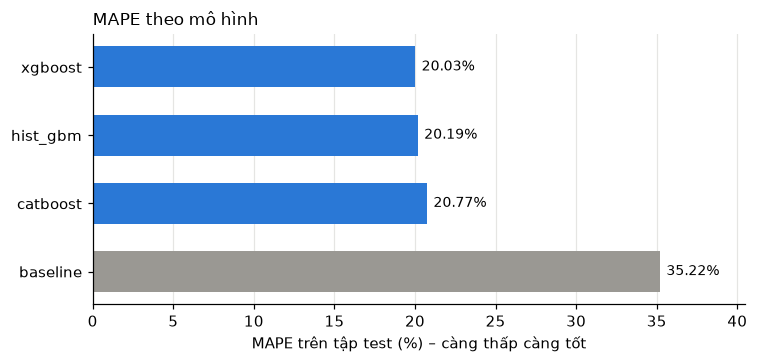

In [8]:
plot = comparison["mape"].sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(7, 3.4))
colors = [GRAY if m == "baseline" else BLUE for m in plot.index]
bars = ax.barh(plot.index, plot.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in plot.values], padding=4, fontsize=9)
ax.set_xlabel("MAPE trên tập test (%) – càng thấp càng tốt")
ax.set_title("MAPE theo mô hình", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, plot.max() * 1.15)
plt.tight_layout()
plt.show()

## 7. Sai số theo loại hình bất động sản

In [9]:
by_type = {}
for name in list(predictions) + ["baseline"]:
    pred = baseline_pred.to_numpy() if name == "baseline" else predictions[name]
    ape = np.abs(pred - test["price_vnd"].to_numpy()) / test["price_vnd"].to_numpy()
    by_type[name] = pd.Series(ape, index=test.index).groupby(test["property_type"]).mean()
by_type = pd.DataFrame(by_type).T.loc[comparison.index] * 100
print("MAPE (%) theo loại hình; số tin test:", test["property_type"].value_counts().to_dict())
by_type.round(2)

MAPE (%) theo loại hình; số tin test: {'Nhà ở': 4274, 'Căn hộ/Chung cư': 808, 'Đất': 666}


property_type,Căn hộ/Chung cư,Nhà ở,Đất
model,,,
xgboost,13.8400,19.1000,33.4900
hist_gbm,14.0600,19.1700,34.1500
catboost,15.6800,19.6800,33.9100
baseline,23.7500,31.9900,69.8300


## 8. Chia ngẫu nhiên 70/30 – để so sánh

Chia ngẫu nhiên cho phép tin cùng tuần, tin đăng lại nằm ở cả train và test. Nếu MAPE ở đây thấp hơn
nhiều so với chia theo thời gian thì cách chia ngẫu nhiên đánh giá quá lạc quan.

In [10]:
rand_train, rand_test = train_test_split(df, test_size=0.3, random_state=42)
rx_train, rx_test = prepare(rand_train), prepare(rand_test)
random_mape = {}
for name, model in candidates.items():
    fresh = clone(model).fit(rx_train, rand_train[TARGET].astype(float))
    random_mape[name] = metrics(rand_test["price_vnd"], np.exp(fresh.predict(rx_test)))["mape"]
split_compare = pd.DataFrame({
    "mape_theo_thoi_gian": comparison["mape"].drop("baseline"),
    "mape_ngau_nhien": pd.Series(random_mape),
})
split_compare["chenh_lech"] = split_compare["mape_theo_thoi_gian"] - split_compare["mape_ngau_nhien"]
split_compare

,mape_theo_thoi_gian,mape_ngau_nhien,chenh_lech
catboost,0.2077,0.2088,-0.0011
hist_gbm,0.2019,0.2040,-0.0021
xgboost,0.2003,0.2049,-0.0046


## 9. Mô hình tốt nhất: dự đoán so với giá thật

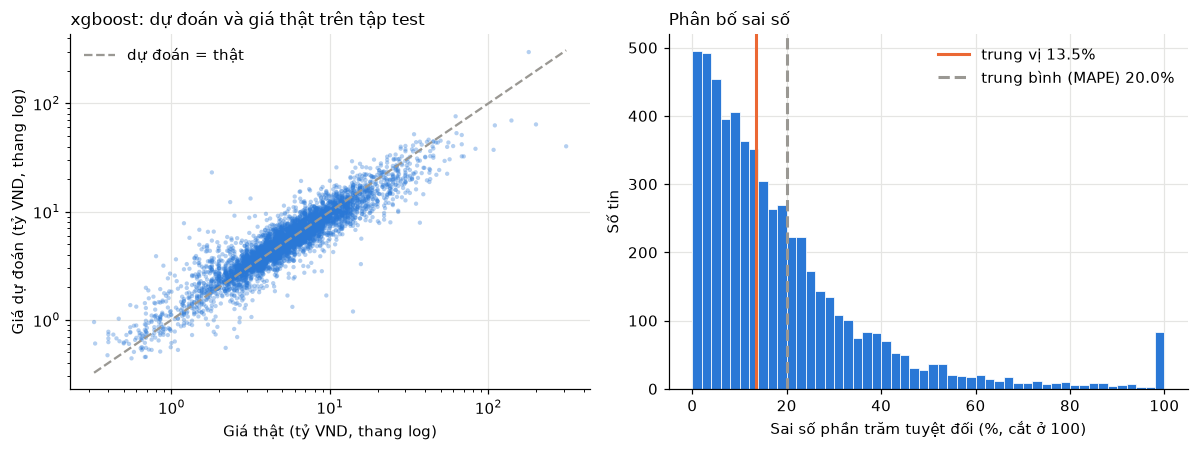

In [11]:
best = comparison.drop("baseline").index[0]
pred = predictions[best]
actual = test["price_vnd"].to_numpy()
ape = np.abs(pred - actual) / actual

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.scatter(actual / 1e9, pred / 1e9, s=8, alpha=0.35, color=BLUE, edgecolors="none")
lims = [min(actual.min(), pred.min()) / 1e9, max(actual.max(), pred.max()) / 1e9]
ax.plot(lims, lims, color=GRAY, lw=1.5, ls="--", label="dự đoán = thật")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Giá thật (tỷ VND, thang log)"); ax.set_ylabel("Giá dự đoán (tỷ VND, thang log)")
ax.set_title(f"{best}: dự đoán và giá thật trên tập test", loc="left", fontsize=11)
ax.legend(frameon=False)

ax = axes[1]
ax.hist(np.clip(ape * 100, 0, 100), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(np.median(ape) * 100, color=ORANGE, lw=2, label=f"trung vị {np.median(ape) * 100:.1f}%")
ax.axvline(ape.mean() * 100, color=GRAY, lw=2, ls="--", label=f"trung bình (MAPE) {ape.mean() * 100:.1f}%")
ax.set_xlabel("Sai số phần trăm tuyệt đối (%, cắt ở 100)"); ax.set_ylabel("Số tin")
ax.set_title("Phân bố sai số", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

MAPE (trung bình) cao hơn trung vị vì một ít tin có sai số rất lớn kéo trung bình lên.
Những tin đó là nguồn sai số chính; xem chúng ở ô dưới.

In [12]:
worst = test.assign(du_doan_ty=pred / 1e9, gia_that_ty=actual / 1e9, ape=ape)
worst.sort_values("ape", ascending=False)[
    ["property_type", "district", "area_m2", "gia_that_ty", "du_doan_ty", "ape"]].head(10)

,property_type,district,area_m2,gia_that_ty,du_doan_ty,ape
11836,Đất,Quận 7,350.0000,1.8000,23.0584,11.8102
7935,Đất,Huyện Hóc Môn,244.0000,1.2000,7.8250,5.5209
21941,Đất,Huyện Củ Chi,1415.0000,2.3500,12.2645,4.2189
19944,Đất,Huyện Hóc Môn,98.0000,0.8000,3.8794,3.8492
11965,Đất,Quận 12,138.1999,1.5000,6.8066,3.5377
4042,Đất,Huyện Bình Chánh,850.0000,1.3000,5.7349,3.4115
13757,Đất,Huyện Nhà Bè,1579.0000,3.1580,13.2430,3.1935
18801,Nhà ở,Quận 12,100.0000,1.7000,6.5160,2.8329
7996,Đất,Huyện Củ Chi,855.0999,2.5000,9.1871,2.6748
14824,Nhà ở,Huyện Củ Chi,37.0000,0.8900,3.1704,2.5623


## 10. Đặc trưng quan trọng

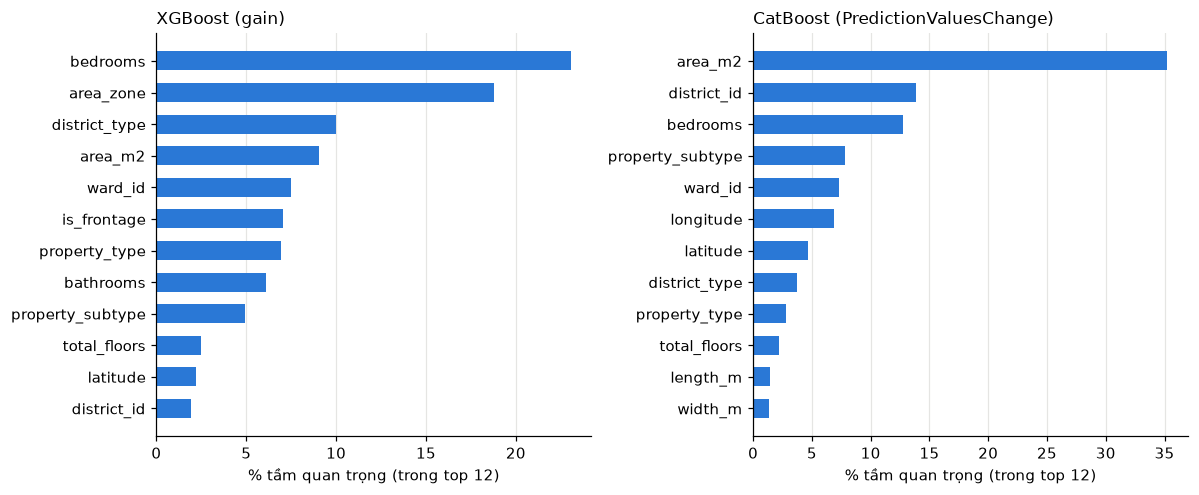

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
xgb = candidates["xgboost"]
imp_xgb = pd.Series(xgb.named_steps["model"].feature_importances_,
                    index=xgb.named_steps["prep"].get_feature_names_out()).nlargest(12)
cat = candidates["catboost"].named_steps["model"]
imp_cat = pd.Series(cat.get_feature_importance(), index=cat.feature_names_).nlargest(12)
for ax, imp, title in [(axes[0], imp_xgb, "XGBoost (gain)"),
                       (axes[1], imp_cat, "CatBoost (PredictionValuesChange)")]:
    imp = imp / imp.sum() * 100
    ax.barh(imp.index[::-1], imp.values[::-1], color=BLUE, height=0.6)
    ax.set_xlabel("% tầm quan trọng (trong top 12)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 11. Sai số theo phân khúc giá và theo quận

Hai câu hỏi:
1. Mô hình có **lệch có hệ thống** không – đoán cao quá ở nhà rẻ, thấp quá ở nhà đắt?
2. Khu vực nào mô hình đoán kém?

Ngoài MAPE (độ lớn sai số), ta xem **sai số có dấu** `(dự đoán − thật) / thật`:
dương là đoán **cao hơn** giá thật, âm là đoán **thấp hơn**. Trung vị của nó đo độ lệch (bias).

In [14]:
SEGMENT_BINS = [0, 2e9, 4e9, 7e9, 12e9, 20e9, np.inf]
SEGMENT_LABELS = ["< 2 tỷ", "2–4 tỷ", "4–7 tỷ", "7–12 tỷ", "12–20 tỷ", "> 20 tỷ"]

errors = test[["property_type", "district", "price_vnd"]].assign(
    pred=predictions[best],
    signed=lambda d: d["pred"] / d["price_vnd"] - 1,
    ape=lambda d: (d["pred"] / d["price_vnd"] - 1).abs(),
)


def segment_table(frame, by):
    return frame.groupby(by, observed=True).agg(
        so_tin=("ape", "size"),
        mape=("ape", "mean"),
        mdape=("ape", "median"),
        lech_trung_vi=("signed", "median"),
        ty_le_doan_cao=("signed", lambda s: (s > 0).mean()),
    )


errors["phan_khuc_gia_that"] = pd.cut(errors["price_vnd"], SEGMENT_BINS, labels=SEGMENT_LABELS)
errors["phan_khuc_gia_du_doan"] = pd.cut(errors["pred"], SEGMENT_BINS, labels=SEGMENT_LABELS)
by_actual = segment_table(errors, "phan_khuc_gia_that")
by_predicted = segment_table(errors, "phan_khuc_gia_du_doan")
print(f"Mô hình: {best}. Theo phân khúc GIÁ THẬT:")
by_actual

Mô hình: xgboost. Theo phân khúc GIÁ THẬT:


,so_tin,mape,mdape,lech_trung_vi,ty_le_doan_cao
phan_khuc_gia_that,,,,,
< 2 tỷ,449,0.4901,0.2566,0.2057,0.7305
2–4 tỷ,1383,0.1875,0.1283,0.0413,0.5973
4–7 tỷ,2172,0.1549,0.1146,0.0067,0.5175
7–12 tỷ,1137,0.1645,0.1288,-0.0518,0.3879
12–20 tỷ,382,0.2197,0.2035,-0.1415,0.2723
> 20 tỷ,225,0.2869,0.2676,-0.2377,0.2089


In [15]:
print("Theo phân khúc GIÁ DỰ ĐOÁN:")
by_predicted

Theo phân khúc GIÁ DỰ ĐOÁN:


,so_tin,mape,mdape,lech_trung_vi,ty_le_doan_cao
phan_khuc_gia_du_doan,,,,,
< 2 tỷ,370,0.2852,0.2106,-0.0183,0.4676
2–4 tỷ,1332,0.1952,0.1291,-0.0059,0.4872
4–7 tỷ,2245,0.1707,0.1171,0.0041,0.5091
7–12 tỷ,1259,0.1954,0.1425,0.0046,0.5091
12–20 tỷ,373,0.2711,0.2070,-0.0001,0.4987
> 20 tỷ,169,0.3282,0.2217,-0.0139,0.4615


**Vì sao xem cả hai cách chia?** Chia theo giá thật luôn tạo ra một độ lệch "giả": nhóm rẻ nhất gom cả
những tin có giá rao thấp bất thường, nên mô hình *có vẻ* đoán cao ở nhóm rẻ và đoán thấp ở nhóm đắt
(hiện tượng hồi quy về trung bình). Chia theo giá dự đoán thì không bị hiệu ứng này – nó trả lời
"khi mô hình nói X tỷ, thì sai bao nhiêu". Nếu độ lệch chỉ xuất hiện ở cách chia thứ nhất mà
biến mất ở cách chia thứ hai, đó là hiệu ứng thống kê chứ không phải lỗi của mô hình.

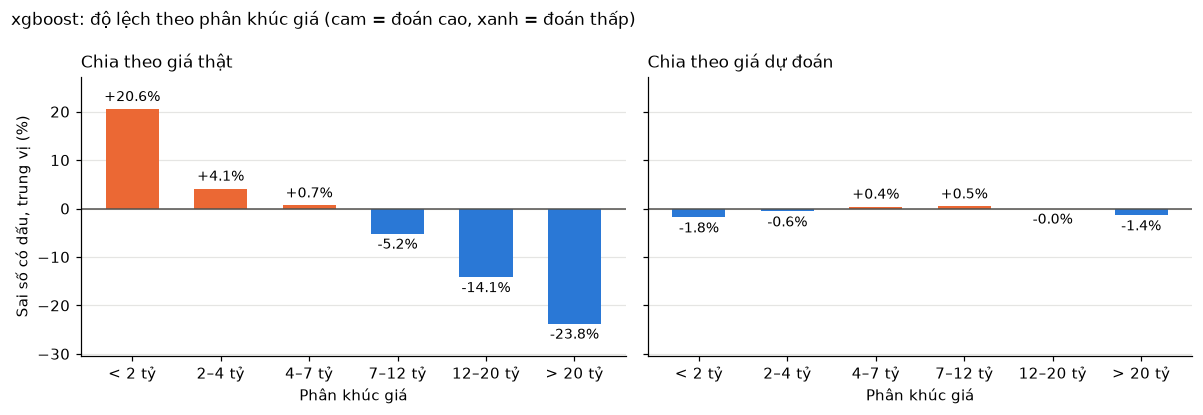

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, table, title in [(axes[0], by_actual, "Chia theo giá thật"),
                         (axes[1], by_predicted, "Chia theo giá dự đoán")]:
    values = table["lech_trung_vi"] * 100
    colors = [ORANGE if v > 0 else BLUE for v in values]
    bars = ax.bar(table.index.astype(str), values, color=colors, width=0.6)
    ax.bar_label(bars, labels=[f"{v:+.1f}%" for v in values], padding=3, fontsize=9)
    ax.axhline(0, color="#52514e", lw=1)
    ax.margins(y=0.15)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Phân khúc giá")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Sai số có dấu, trung vị (%)")
fig.suptitle(f"{best}: độ lệch theo phân khúc giá (cam = đoán cao, xanh = đoán thấp)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
MIN_LISTINGS = 30
by_district = segment_table(errors, "district")
by_district = by_district[by_district["so_tin"] >= MIN_LISTINGS].sort_values("mape")
print(f"{len(by_district)} quận có >= {MIN_LISTINGS} tin trong tập test, xếp theo MAPE tăng dần:")
by_district

21 quận có >= 30 tin trong tập test, xếp theo MAPE tăng dần:


,so_tin,mape,mdape,lech_trung_vi,ty_le_doan_cao
district,,,,,
Quận 8,349,0.1418,0.1023,0.0221,0.5673
Quận Tân Phú,504,0.1526,0.1165,-0.0080,0.4782
Quận 6,156,0.1550,0.1204,0.0111,0.5256
Quận Phú Nhuận,162,0.1566,0.1384,-0.0171,0.4691
Quận 4,71,0.1587,0.1195,-0.0323,0.4507
Quận Gò Vấp,566,0.1592,0.1268,0.0072,0.5318
Quận 11,148,0.1626,0.1223,0.0020,0.5068
Quận Bình Tân,634,0.1632,0.1148,-0.0003,0.5000
Quận 3,73,0.1693,0.1246,-0.0056,0.4795


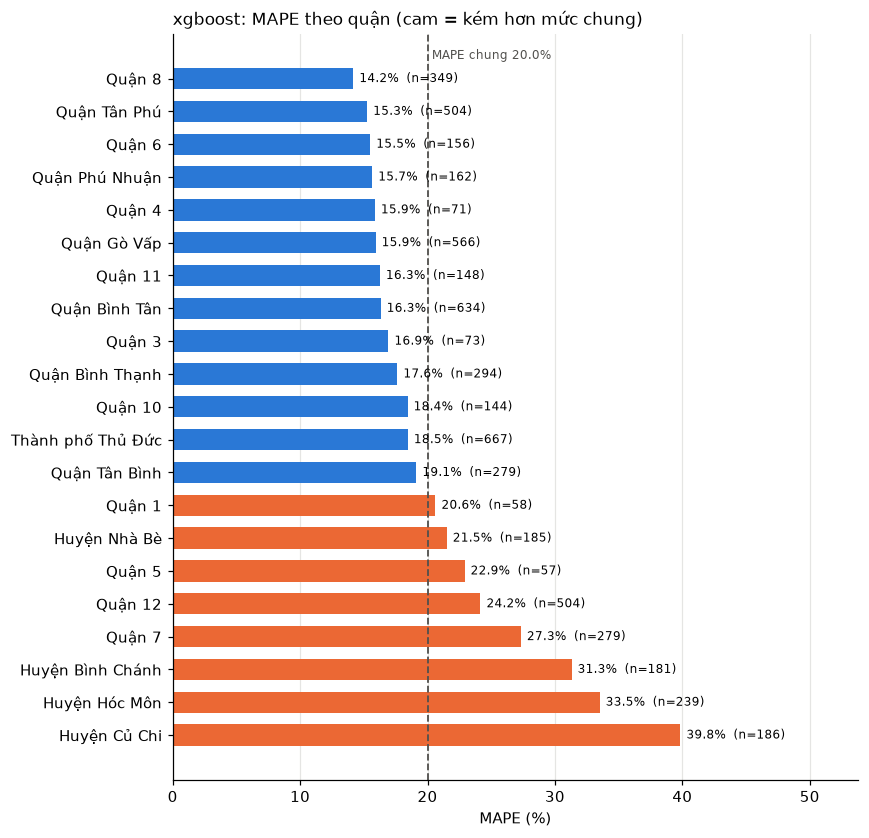

In [18]:
plot = by_district.sort_values("mape")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(plot) + 1))
overall = errors["ape"].mean() * 100
colors = [ORANGE if v * 100 > overall else BLUE for v in plot["mape"]]
bars = ax.barh(plot.index, plot["mape"] * 100, color=colors, height=0.65)
ax.bar_label(bars, labels=[f"{v * 100:.1f}%  (n={n})" for v, n in zip(plot["mape"], plot["so_tin"])],
             padding=4, fontsize=8)
ax.axvline(overall, color="#52514e", lw=1.2, ls="--")
ax.text(overall, -0.9, f" MAPE chung {overall:.1f}%", fontsize=8, color="#52514e", va="top")
ax.invert_yaxis()
ax.set_xlabel("MAPE (%)")
ax.set_title(f"{best}: MAPE theo quận (cam = kém hơn mức chung)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, plot["mape"].max() * 100 * 1.35)
plt.tight_layout()
plt.show()

In [19]:
# Quận đoán kém nhất: do loại hình nào?
worst_districts = by_district.sort_values("mape", ascending=False).head(5).index
mix = (errors[errors["district"].isin(worst_districts)]
       .groupby(["district", "property_type"]).agg(so_tin=("ape", "size"), mape=("ape", "mean"))
       .reset_index())
mix["mape"] = (mix["mape"] * 100).round(1)
mix.pivot(index="district", columns="property_type", values=["so_tin", "mape"]).loc[worst_districts]

so_tin                              mape          \
property_type    Căn hộ/Chung cư    Nhà ở      Đất Căn hộ/Chung cư   Nhà ở   
district                                                                     
Huyện Củ Chi                 NaN  31.0000 155.0000             NaN 42.7000   
Huyện Hóc Môn             1.0000 148.0000  90.0000          1.3000 28.0000   
Huyện Bình Chánh         39.0000 104.0000  38.0000         14.7000 24.4000   
Quận 7                   87.0000 182.0000  10.0000         17.1000 26.0000   
Quận 12                  17.0000 407.0000  80.0000          6.5000 24.7000   

                           
property_type         Đất  
district                   
Huyện Củ Chi      39.3000  
Huyện Hóc Môn     43.0000  
Huyện Bình Chánh  67.2000  
Quận 7           141.2000  
Quận 12           25.1000

## 12. Tóm tắt

In [20]:
best_row = comparison.loc[best]
base_row = comparison.loc["baseline"]
print(f"Mô hình tốt nhất: {best}")
print(f"  MAPE {best_row.mape:.2%} | MdAPE {best_row.mdape:.2%} | R2(log) {best_row.r2_log:.3f} "
      f"| {best_row.within_20pct:.1%} tin sai số <= 20%")
print(f"  Giảm {1 - best_row.mape / base_row.mape:.0%} sai số so với baseline ({base_row.mape:.2%})")
second = comparison.drop(["baseline", best]).index[0]
print(f"  Hơn mô hình thứ hai ({second}) {(comparison.loc[second].mape - best_row.mape) * 100:.2f} điểm MAPE")

Mô hình tốt nhất: xgboost
  MAPE 20.03% | MdAPE 13.49% | R2(log) 0.855 | 66.0% tin sai số <= 20%
  Giảm 43% sai số so với baseline (35.22%)
  Hơn mô hình thứ hai (hist_gbm) 0.16 điểm MAPE
